# 01 · Anatomy of the Kryptonite-3.0 datasets (Figure 1)

**Question.** Is there structure in Kryptonite-n that a learner could exploit, and what does it look like?

Everything here is computed from the **training and validation parts of split seed 0** (the test parts are
never used in this notebook).  We (i) check the input distribution, (ii) select relevant coordinates with
greedy forward selection, (iii) estimate the label function on those coordinates and analyse its Fourier
spectrum, and (iv) compare the function across Kryptonite-20/30/40, KryptoNet-40's pretraining task and
Kryptonite-40-Adapt.

In [1]:
import itertools
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.optimize import linprog

from krypto.data import load, split, bits
from krypto.fourier import truth_table, spectrum_of_table, degree_weights, influences
from krypto.selection import greedy_forward_selection, LookupTable
from krypto.lora import load_base
from krypto.mlp import logits
from krypto.energy import track
from krypto.plotting import use_paper_style, save, FULL, COLORS

print("plot backend:", use_paper_style())
NAMES = {20: "kryptonite-20", 30: "kryptonite-30", 40: "kryptonite-40", "adapt": "kryptonite-40-adapt"}

plot backend: usetex


## 1. Inputs are noisy bits
Every feature is $x_i = b_i + \varepsilon_i$ with $b_i\in\{-1,+1\}$ and small Gaussian noise, so `sign(x)` recovers
the bit exactly ($|x_i| > 0.5$ everywhere).  No single coordinate is correlated with the label.

In [2]:
for key, name in NAMES.items():
    X, y = load(name)
    resid = np.abs(X) - 1
    s = 2 * y - 1
    max_corr = np.abs(bits(X).T @ s / len(s)).max()
    print(f"{name:22s} N={len(y):6d} n={X.shape[1]}  min|x|={np.abs(X).min():.3f}  noise sd={resid.std():.3f}  "
          f"P(y=1)={y.mean():.3f}  max_i |corr(b_i, y)|={max_corr:.3f}  (1/sqrt(N)={1/np.sqrt(len(y)):.3f})")

kryptonite-20          N= 12000 n=20  min|x|=0.556  noise sd=0.100  P(y=1)=0.496  max_i |corr(b_i, y)|=0.026  (1/sqrt(N)=0.009)
kryptonite-30          N= 20000 n=30  min|x|=0.500  noise sd=0.100  P(y=1)=0.499  max_i |corr(b_i, y)|=0.015  (1/sqrt(N)=0.007)
kryptonite-40          N= 32000 n=40  min|x|=0.493  noise sd=0.100  P(y=1)=0.498  max_i |corr(b_i, y)|=0.015  (1/sqrt(N)=0.006)
kryptonite-40-adapt    N=  4000 n=40  min|x|=0.574  noise sd=0.100  P(y=1)=0.513  max_i |corr(b_i, y)|=0.029  (1/sqrt(N)=0.016)


## 2. Greedy forward selection finds exactly 10 relevant coordinates
Selection minimises the validation log-loss of a lookup table on the selected bits (`krypto/selection.py`).
For the KryptoNet-40 pretraining task (Kryptonite-40-Pre, not released) we analyse the function computed by
KryptoNet-40 itself on 200,000 synthetic inputs drawn from the input distribution above.

In [3]:
data, sel = {}, {}
with track("01_selection"):
    for key, name in NAMES.items():
        X, y = load(name)
        X_tr, y_tr, X_va, y_va, _, _ = split(X, y, seed=0, val=0.16 if key == "adapt" else 0.2)
        S, hist = greedy_forward_selection(X_tr, y_tr, X_va, y_va)
        data[key], sel[key] = (np.r_[X_tr, X_va], np.r_[y_tr, y_va]), sorted(S)
        print(f"{name:22s} selected k={len(S):2d}: {sorted(S)}   val log-loss {hist[0]:.3f} -> {hist[-1]:.3f}")

    rng = np.random.default_rng(0)
    B = rng.choice([-1.0, 1.0], size=(200_000, 40))
    X_pre = (B + 0.1 * rng.standard_normal(B.shape)).astype(np.float32)
    y_pre = (logits(load_base(), X_pre) > 0).astype(int)
    S, _ = greedy_forward_selection(X_pre[:150_000], y_pre[:150_000], X_pre[150_000:], y_pre[150_000:])
    data["pre"], sel["pre"] = (X_pre, y_pre), sorted(S)
    print(f"{'KryptoNet-40 (Pre)':22s} selected k={len(S):2d}: {sorted(S)}")

kryptonite-20          selected k=10: [0, 1, 2, 4, 5, 7, 9, 10, 12, 15]   val log-loss 0.693 -> 0.202


kryptonite-30          selected k=10: [2, 5, 10, 11, 14, 17, 19, 20, 26, 28]   val log-loss 0.693 -> 0.192


kryptonite-40          selected k=10: [6, 7, 12, 15, 21, 24, 25, 30, 36, 39]   val log-loss 0.693 -> 0.169
kryptonite-40-adapt    selected k=10: [3, 6, 8, 10, 13, 17, 19, 26, 37, 38]   val log-loss 0.693 -> 0.290


KryptoNet-40 (Pre)     selected k=10: [0, 3, 6, 8, 10, 13, 17, 26, 37, 38]
[track] 01_selection: 8.7 s


## 3. The label function on the selected bits
`truth_table` takes the majority label of each of the $2^{10}=1024$ bit patterns (training+validation data).
We report the Fourier weight per degree, the influence of each variable and the label-noise rate (the
disagreement between labels and the majority truth table).

In [4]:
tables, spectra = {}, {}
for key in ["pre", 20, 30, 40, "adapt"]:
    (X, y), S = data[key], sel[key]
    tt = truth_table(X, y, S)
    tables[key], spectra[key] = tt, spectrum_of_table(tt)
    W = degree_weights(spectra[key])
    inf = influences(spectra[key])
    noise = 1 - LookupTable(S).fit(X, y).score(X, y)
    print(f"{str(key):6s} W^(=d), d=0..10: {np.round(W, 3)}   influences: {sorted(np.round(inf, 3))}   "
          f"in-sample label noise ~ {noise:.3f}")
print("Distinct |Fourier coefficient| values x 64:", np.unique(np.round(np.abs(spectra[40]) * 64, 3)))

pre    W^(=d), d=0..10: [0.    0.    0.02  0.053 0.132 0.182 0.228 0.182 0.132 0.053 0.02 ]   influences: [np.float64(0.375), np.float64(0.375), np.float64(0.375), np.float64(0.375), np.float64(0.625), np.float64(0.625), np.float64(0.625), np.float64(0.625), np.float64(1.0), np.float64(1.0)]   in-sample label noise ~ 0.001
20     W^(=d), d=0..10: [0.    0.    0.02  0.054 0.132 0.183 0.226 0.182 0.132 0.051 0.019]   influences: [np.float64(0.373), np.float64(0.373), np.float64(0.381), np.float64(0.381), np.float64(0.623), np.float64(0.623), np.float64(0.623), np.float64(0.623), np.float64(0.994), np.float64(0.994)]   in-sample label noise ~ 0.039
30     W^(=d), d=0..10: [0.    0.    0.02  0.053 0.132 0.182 0.228 0.182 0.132 0.053 0.02 ]   influences: [np.float64(0.375), np.float64(0.375), np.float64(0.375), np.float64(0.375), np.float64(0.625), np.float64(0.625), np.float64(0.625), np.float64(0.625), np.float64(1.0), np.float64(1.0)]   in-sample label noise ~ 0.039
40     W^(=d), d=0..1

## 4. One Boolean function, five tasks
All five tasks have the same influence profile (2 variables of influence 1, 4 of 5/8, 4 of 3/8).  We search over
the permutations that respect these classes ($2!\,4!\,4! = 1152$) and find an exact match with KryptoNet-40's
function.  Kryptonite-40-Adapt is the pretraining task with coordinate 0 replaced by coordinate 19.

In [5]:
codes = np.arange(1024)
code_bits = (codes[:, None] >> np.arange(10)) & 1


def influence_classes(F):
    """Variables ranked by influence: the top 2 (parity pair), the next 4 and the last 4 (gadget bits)."""
    order = list(np.argsort(-influences(F), kind="stable"))
    return [sorted(order[:2]), sorted(order[2:6]), sorted(order[6:])]


def best_permutation(ref_tt, tt):
    """Best agreement between truth tables over class-respecting variable permutations."""
    c_ref, c = influence_classes(spectrum_of_table(ref_tt)), influence_classes(spectrum_of_table(tt))
    best = (0.0, None)
    for p0 in itertools.permutations(c[0]):
        for p1 in itertools.permutations(c[1]):
            for p2 in itertools.permutations(c[2]):
                perm = np.zeros(10, int)
                for cls_ref, cls in zip(c_ref, (p0, p1, p2)):
                    perm[list(cls_ref)] = cls
                agree = (ref_tt == tt[(code_bits << perm).sum(1)]).mean()
                if agree > best[0]:
                    best = (agree, perm)
    return best


mapping = {}
for key in [20, 30, 40, "adapt"]:
    agree, perm = best_permutation(tables["pre"], tables[key])
    mapping[key] = {sel["pre"][v]: sel[key][perm[v]] for v in range(10)}
    print(f"{str(key):6s} agreement with KryptoNet-40's function: {agree:.4f}   pre-coordinate -> coordinate: {mapping[key]}")

X_ad, y_ad = data["adapt"]
X_sw = X_ad.copy(); X_sw[:, 0] = X_ad[:, 19]
print("\nKryptoNet-40 zero-shot accuracy on Adapt (train+val):", ((logits(load_base(), X_ad) > 0) == y_ad).mean().round(4))
print("... after moving coordinate 19 into slot 0:          ", ((logits(load_base(), X_sw) > 0) == y_ad).mean().round(4))

20     agreement with KryptoNet-40's function: 0.9971   pre-coordinate -> coordinate: {0: 4, 3: 1, 6: 0, 8: 10, 10: 9, 13: 15, 17: 2, 26: 12, 37: 7, 38: 5}
30     agreement with KryptoNet-40's function: 1.0000   pre-coordinate -> coordinate: {0: 10, 3: 26, 6: 20, 8: 28, 10: 11, 13: 14, 17: 2, 26: 5, 37: 17, 38: 19}


40     agreement with KryptoNet-40's function: 1.0000   pre-coordinate -> coordinate: {0: 6, 3: 12, 6: 39, 8: 24, 10: 25, 13: 36, 17: 21, 26: 30, 37: 15, 38: 7}
adapt  agreement with KryptoNet-40's function: 0.9541   pre-coordinate -> coordinate: {0: 10, 3: 3, 6: 6, 8: 8, 10: 19, 13: 13, 17: 17, 26: 26, 37: 37, 38: 38}



KryptoNet-40 zero-shot accuracy on Adapt (train+val): 0.4931
... after moving coordinate 19 into slot 0:           0.9591


## 5. Structure of the function: a 2-bit parity XOR two 4-bit gadgets
If $f = \chi_{P}\,h_A\,h_B$ with $P$ the influence-1 pair and $h_A, h_B$ on disjoint blocks, then
$\hat f(P\cup S\cup T)\hat f(P) = \hat f(P\cup S)\hat f(P\cup T)$ whenever $S, T$ lie in different blocks.
We use this identity to recover the blocks, and a linear program to find the polynomial-threshold degree of
$f$, i.e. the smallest $d$ with $f=\mathrm{sign}(p)$ for a degree-$d$ polynomial $p$.

In [6]:
F, S = spectra["pre"], sel["pre"]
pos = {v: i for i, v in enumerate(S)}
cls = influence_classes(F)
pair = [S[i] for i in cls[0]]
others = [v for v in S if v not in pair]


def coef(vs):
    m = sum(1 << pos[v] for v in pair + list(vs))
    return F[m]


linked = [(u, v) for u, v in itertools.combinations(others, 2)
          if abs(coef([u, v]) * coef([]) - coef([u]) * coef([v])) > 1e-9]   # u, v cannot be in different blocks
parent = {v: v for v in others}                                           # union-find over linked pairs


def root(v):
    while parent[v] != v:
        v = parent[v]
    return v


for u, v in linked:
    parent[root(u)] = root(v)
blocks = [sorted(v for v in others if root(v) == r) for r in sorted({root(v) for v in others})]
print("parity pair:", pair, "  gadget blocks:", blocks)
for blk in blocks:
    h = np.array([coef(T) for s in range(5) for T in itertools.combinations(blk, s)])
    print(f"  block {blk}: |coefficients| x 64 =", sorted(set(np.round(np.abs(h) * 64, 3))))

B10 = np.where(code_bits, -1.0, 1.0)
tt = tables["pre"]
for d in range(1, 11):
    cols = [np.ones(1024)] + [B10[:, list(T)].prod(1) for s in range(1, d + 1) for T in itertools.combinations(range(10), s)]
    A = np.stack(cols, 1)
    res = linprog(np.zeros(A.shape[1]), A_ub=-(tt[:, None] * A), b_ub=-np.ones(1024),
                  bounds=[(None, None)] * A.shape[1], method="highs")
    if res.status == 0:
        print(f"f is a degree-{d} polynomial threshold function (and not of degree {d - 1}).")
        PTF_DEGREE = d
        break

parity pair: [0, 10]   gadget blocks: [[3, 6, 17, 37], [8, 13, 26, 38]]
  block [3, 6, 17, 37]: |coefficients| x 64 = [np.float64(3.0), np.float64(9.0)]
  block [8, 13, 26, 38]: |coefficients| x 64 = [np.float64(3.0), np.float64(9.0)]


f is a degree-6 polynomial threshold function (and not of degree 5).


## Figure 1

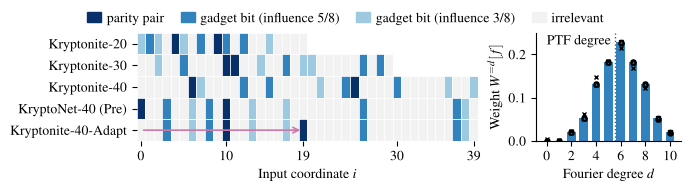

In [7]:
roles = np.full((5, 40), np.nan)           # 0 irrelevant, 1 weak gadget, 2 strong gadget, 3 parity pair
rows = [(20, "Kryptonite-20"), (30, "Kryptonite-30"), (40, "Kryptonite-40"), ("pre", "KryptoNet-40 (Pre)"),
        ("adapt", "Kryptonite-40-Adapt")]
for r, (key, _) in enumerate(rows):
    n = 40 if key in ("pre", "adapt") else key
    roles[r, :n] = 0
    c = influence_classes(spectra[key])
    for role, members in zip((3, 2, 1), c):
        for i in members:
            roles[r, sel[key][i]] = role

fig, (ax, bx) = plt.subplots(1, 2, figsize=(FULL, 1.8), gridspec_kw={"width_ratios": [2.35, 1]})
cmap = ListedColormap(["#f2f2f2", "#9ecae1", "#3182bd", "#08306b"])
cmap.set_bad("white")
ax.imshow(np.ma.masked_invalid(roles), cmap=cmap, vmin=-0.5, vmax=3.5, aspect="auto", interpolation="nearest")
ax.set_yticks(range(5)); ax.set_yticklabels([lab for _, lab in rows])
ax.set_xticks([0, 10, 19, 30, 39])
ax.set_xlabel("Input coordinate $i$")
ax.set_xticks(np.arange(-0.5, 40, 1), minor=True); ax.set_yticks(np.arange(-0.5, 5, 1), minor=True)
ax.grid(which="minor", color="white", lw=0.6); ax.tick_params(which="minor", length=0)
for side in ("top", "right", "left", "bottom"):
    ax.spines[side].set_visible(False)
ax.annotate("", xy=(19, 4), xytext=(0, 4), arrowprops=dict(arrowstyle="->", color="#CC79A7", lw=1.2))
handles = [plt.Rectangle((0, 0), 1, 1, color=cmap(i)) for i in (3, 2, 1, 0)]
fig.legend(handles, ["parity pair", "gadget bit (influence 5/8)", "gadget bit (influence 3/8)", "irrelevant"],
           ncol=4, loc="outside upper center", handlelength=1.0, columnspacing=1.2, handletextpad=0.4)

W = degree_weights(spectra[40])
bx.bar(range(11), W, color="#3182bd", width=0.7, label="Kryptonite-40")
for key, mk in [(20, "o"), (30, "s"), ("pre", "^"), ("adapt", "x")]:
    bx.plot(range(11), degree_weights(spectra[key]), mk, ms=3.5, mfc="none", color="k", lw=0)
bx.axvline(PTF_DEGREE - 0.5, color=COLORS["gray"], ls=":", lw=1)
bx.text(PTF_DEGREE - 0.8, 0.245, "PTF degree", va="top", ha="right")
bx.set_xlabel("Fourier degree $d$"); bx.set_ylabel(r"Weight $W^{=d}[f]$")
bx.set_xticks([0, 2, 4, 6, 8, 10]); bx.set_ylim(0, 0.25)
save(fig, "fig1_anatomy")
plt.show()

**Reading Figure 1.** Left: every task reads exactly 10 coordinates; the role pattern (2 parity bits, 4+4 gadget
bits) is identical, only the positions differ, and Adapt differs from KryptoNet-40's pretraining task by moving one
parity bit from coordinate 0 to 19 (arrow).  Right: the Fourier weight of the label function lies almost entirely
at degree $\ge 4$ (bars: Kryptonite-40; markers: the other four tasks, which coincide), and $f$ is a polynomial
threshold function of degree 6 on its 10 relevant bits.

In [8]:
from krypto.stats import save_json
save_json({"selected": {str(k): v for k, v in sel.items()},
           "degree_weights": {str(k): degree_weights(v).tolist() for k, v in spectra.items()},
           "mapping_from_pre": {str(k): {str(a): int(b) for a, b in m.items()} for k, m in mapping.items()},
           "pair": pair, "blocks": blocks, "ptf_degree": PTF_DEGREE,
           "truth_table_40": tables[40].tolist(), "selected_40": sel[40]}, "anatomy.json")